---
title: "Linear systems of equations"
subtitle: "Lecture 13: Chapter 5: Linear systems of equations"
code-fold: false
format:
  html: default
  pdf: default
---

{{< include ../extras/_lecture-header.html >}}

In [17]:
# | include: false

using Plots, LaTeXStrings, Polynomials, LinearAlgebra

# Chebyshev nodes (of the second kind by default), in increasing order
function ChebyshevNodes( n; type=2 )
    if (type == 1)
        return @. cos( (2*(n:-1:0)+1)*pi/(2*(n+1)) )
    else
        return @. cos( (pi/n)*(n:-1:0) )
    end
end

# polynomial interpolant of f on n+1 Chebyshev nodes (Barycentric formula)
function ChebyshevInterpolant( f, n )
    x = ChebyshevNodes(n)
    y = f.(x)

    λ = zeros(n+1)
    λ[1] = 1/2
    λ[n+1] = (-1)^n/2
    for j in 1:(n-1)
        λ[j+1] = (-1)^j
    end

    return t -> t in x ? f(t) : sum( @. λ * y / (t - x) ) / sum( @. λ / (t - x) )
end

# i-th Lagrange polynomial on the n+1 Chebyshev nodes (in the Chebyshev basis)
function Lagrange( i, n )
    x = ChebyshevNodes(n)
    y = [ j==i ? 1 : 0 for j=0:n ]

    return fit( ChebyshevT, x, y )
end

Lagrange (generic function with 1 method)

## Previously.....

- Quadrature rules $\int_a^b f \approx \sum_j w_j f(x_j)$; interpolatory rules use the weights $w_j = \int_a^b \ell_j(x) \mathrm{d}x$,
- Newton-Cotes (equispaced nodes): rectangular, midpoint, trapezoid, and Simpson's rules, and their composite versions with errors $O(h)$, $O(h^2)$, $O(h^2)$, $O(h^4)$,
- Gaussian quadrature: choose the nodes **and** the weights so that the rule is exact for all polynomials of degree $2n+1$,
- Legendre polynomials $P_n$: monic and orthogonal in $L^2([-1,1])$; the Gaussian quadrature nodes are the zeros of $P_{n+1}$,
- For $n = 1$: $\int_{-1}^1 f \approx f\big(-\tfrac{\sqrt3}{3}\big) + f\big(\tfrac{\sqrt3}{3}\big)$ with error $\frac{1}{135}|f^{(4)}(\xi)|$,
- The zeros of $P_{n+1}$ are the eigenvalues of a tridiagonal matrix: this is where linear algebra comes in.

## Linear systems of equations

::: {#exr-l12-warmup name="Warm-up"}

[](../exercises/bank.html#bank-exr-l12-warmup)

1. How would you write the following system of equations as a matrix equation?

$$
\begin{align*}
    3x - y + z &= 1 \\
    x-y-z &= 3\\
    y + z &= 0
\end{align*}
$$

2. Why is there a solution to this equation?
3. Use Cramer's rule to compute the inverse of $A$.
4. Therefore show that $x = 3, y = 4, z = -4$.

::: {.exercise-solution style="display: none;"}

1. 
$$
\begin{align*}
    \begin{pmatrix}
        3 & -1 & 1 \\ 
        1 & -1 & -1 \\
        0 & 1 & 1
    \end{pmatrix}
    \begin{pmatrix}
    x \\ y \\ z
    \end{pmatrix}
    = 
    \begin{pmatrix}
    1 \\ 3 \\ 0
    \end{pmatrix}
\end{align*}
$$

2. The determinant of $A$ is non-zero.

:::

::: {.exercise-solution .draft style="display: none;"}

2. Expanding along the first row, $\det A = 3\big((-1)(1) - (-1)(1)\big) + \big(1 - 0\big) + \big(1 - 0\big) = 2 \not= 0$, so $A$ is invertible and $A\mathbf x = \mathbf b$ has exactly one solution $\mathbf x = A^{-1} \mathbf b$ (for every $\mathbf b$).

3. The cofactors $C_{ij} = (-1)^{i+j} M_{ij}$ (where $M_{ij}$ is the determinant after deleting row $i$ and column $j$) are
$$
\begin{align*}
    \begin{pmatrix}
        C_{11} & C_{12} & C_{13} \\
        C_{21} & C_{22} & C_{23} \\
        C_{31} & C_{32} & C_{33}
    \end{pmatrix}
    = 
    \begin{pmatrix}
        0 & -1 & 1 \\
        2 & 3 & -3 \\
        2 & 4 & -2
    \end{pmatrix}
\end{align*}
$$
and $[A^{-1}]_{ij} = C_{ji} / \det A$, so
$$
\begin{align*}
    A^{-1} = \frac12 \begin{pmatrix} 0 & 2 & 2 \\ -1 & 3 & 4 \\ 1 & -3 & -2 \end{pmatrix}
    = \begin{pmatrix} 0 & 1 & 1 \\ -\tfrac12 & \tfrac32 & 2 \\ \tfrac12 & -\tfrac32 & -1 \end{pmatrix}.
\end{align*}
$$

4. $\mathbf x = A^{-1} \mathbf b = \big( 0 + 3 + 0, -\tfrac12 + \tfrac92 + 0, \tfrac12 - \tfrac92 + 0 \big)^\intercal = (3, 4, -4)^\intercal$. Check: $9 - 4 - 4 = 1$, $3 - 4 + 4 = 3$, $4 - 4 = 0$.

:::

:::

Julia confirmed our findings:

In [18]:
A = [3 -1 1 ; 1 -1 -1; 0 1 1]
b = [1 , 3, 0]

inv(A)

3×3 Matrix{Float64}:
 -5.55112e-17   1.0   1.0
 -0.5           1.5   2.0
  0.5          -1.5  -1.0

In [19]:
inv(A) * b 

3-element Vector{Float64}:
  3.000000000000001
  4.000000000000002
 -4.000000000000002

In [20]:
A \ b

3-element Vector{Float64}:
  3.0000000000000004
  4.000000000000001
 -4.000000000000001

## Examples

Then we saw some examples that involve matrices and relate to previous topics you've seen:

::: {#exm-l12-vandermonde name="Polynomial interpolation (Chapter 3)"}

For distinct points $X = \{ x_0, \dots, x_n \}$ and values $\{y_0,\dots,y_n\}$ (which, in our case, were given by $y_j = f(x_j)$ for some function $f$), consider the *Lagrange interpolation problem*: find $p(x) = a_0 + a_1 x + a_2 x^2 + \dots + a_n x^n$ such that $p(x_j) = y_j$ for $j=0,\dots,n$. We saw that the solution can be written as $p(x) = \sum_{j=0}^n \ell_j(x) y_j$. The problem can also be written as the following matrix equation:

$$
\begin{align}
    V \mathbf a 
    %
    := 
    \begin{pmatrix}
        1 & x_0 & x_0^2 & \cdots & x_0^n \\
         1 & x_1 & x_1^2 & \cdots & x_1^n \\
          1 & x_2 & x_2^2 & \cdots & x_2^n \\
          \vdots & \vdots & \vdots &\ddots & \vdots \\
           1 & x_n & x_n^2 & \cdots & x_n^n
    \end{pmatrix}
    \begin{pmatrix}
        a_0 \\ a_1 \\ a_2 \\ \vdots \\ a_n
    \end{pmatrix}
    %
    = \begin{pmatrix}
        y_0 \\ y_1 \\ y_2 \\ \vdots \\ y_n
    \end{pmatrix},
\end{align}
$$

where the matrix $V$ is known as the *Vandermonde matrix*. Since $p$ exists (and is unique) for any choice of $\mathbf y$, we have already proved that $V$ is invertible and $\mathbf a = V^{-1} \mathbf y$. 

:::

0.39419514906422415
0.3941951490642238


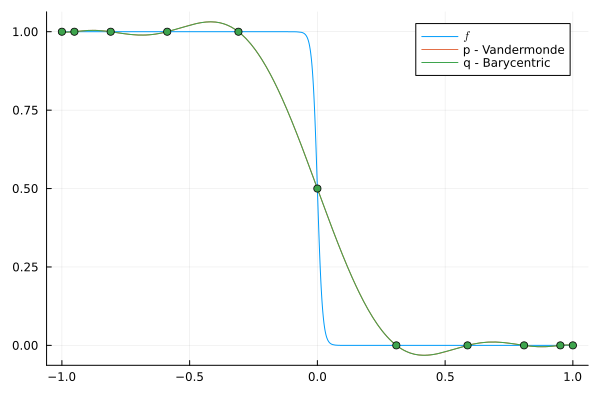

In [21]:
f = x -> 1 / (1 + exp(100 * x) ) 
e = -1:.001:1

N = 10;
X = ChebyshevNodes( N )
Y = f.(X) 
V = X.^(0:N)'

p = Polynomial( V \ Y )
q = ChebyshevInterpolant( f, N )

println( maximum( @. abs( f(e)-p(e) ) ) )
println( maximum( @. abs( f(e)-q(e) ) ) )

plot( f, -1, 1, label=L"f" ) 
plot!( p, -1, 1, label="p - Vandermonde" ) 
plot!( q, -1, 1, label="q - Barycentric" ) 
scatter!( X, Y, primary = false )

::: {#exm-l12-galerkin name="Differential equations (Galerkin method)"}

Suppose you want to solve the differential equation $Lu = f$ where $L$ is some linear differential operator (e.g. $Lu(x) := u''(x) + g(x) u'(x) + h(x) u(x)$ for a general 2nd order linear differential equation). In order to solve this equation numerically, one may *discretise* it: introduce some finite set of functions $\{ \phi_j \}_{j=1}^N$ and suppose that $u \approx \sum_{j=1}^N c_j \phi_j$ for some coefficients $\mathbf c = (c_j)$. Then, multiplying by $\phi_i$ and integrating, one obtains

$$
\begin{align}
    \int \phi_i(x) (Lu)(x) \mathrm{d}x 
    %
    &= \sum_j \int \phi_i(x) (L\phi_j)(x) \mathrm{d}x \,\, c_j \nonumber\\
    %
    &= \int \phi_i(x) f(x) \mathrm{d}x.  
\end{align}
$$

This is the matrix equation $A \mathbf c = \mathbf f$ where

$$
\begin{align}
    A_{ij} &:= \int \phi_i(x) (L\phi_j)(x) \mathrm{d}x \nonumber\\
    f_{i} &:= \int \phi_i(x) f(x) \mathrm{d}x 
\end{align}
$$

Solving this system gives the coefficients in the approximate solution $u$.

:::

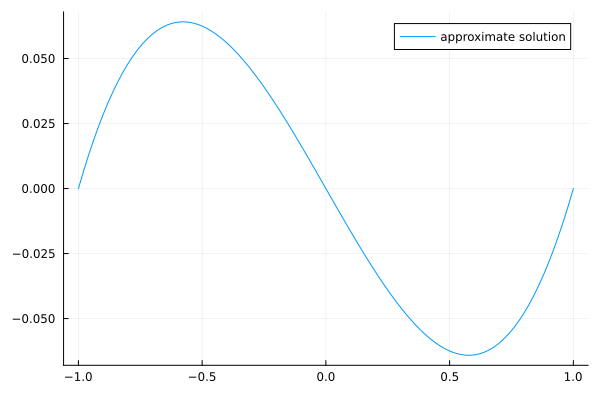

In [22]:
f = x->-x 

n = 100; 
X = ChebyshevNodes( n )[2:end-1]
A = zeros( n-1, n-1 )
S = zeros( n-1, n-1 )
F = zeros( n-1 )

# Approximate f with a polynomial
p = fit(ChebyshevT, X, f.(X))

φ = [ Lagrange( 1, n ) ];
for i = 2:(n-1)
    push!( φ, Lagrange( i, n ) )
end

for i = 1:(n-1) 
    F[i] = integrate( p * φ[i], -1, 1 )
    for j=1:(n-1)
        A[i,j] = integrate( derivative( φ[i] ) * derivative(φ[j]), -1, 1)
    end
end
c = A \ F
u = sum( c .* φ )

plot( u, -1, 1, label="approximate solution")

::: {#exm-l12-companion name="Companion matrices"}

The `roots` function in the Julia package `Polynomials.jl` finds the roots of a (monic) polynomial $p(x) = a_0 + a_1 x + \dots + a_{n-1} x^{n-1} + x^n$ by considering the following *Frobenius companion matrix*:

$$
\begin{align}
    C = \begin{pmatrix}
        0 & 0 & \cdots & 0 & -a_0 \\
        1 &  &  &  & -a_1 \\
        & 1&  & & -a_2 \\
        & & \ddots & & \vdots \\
        & & & 1 & -a_{n-1}
    \end{pmatrix}.
\end{align}
$$

It turns out that $p$ is the characteristic polynomial of $C$: that is, $p(x) = \det\big( xI - C \big)$. Therefore, one may find the roots of $p$ by computing eigenvalues of $C$ (which we will discuss in the following weeks). 

:::

## Cramer's rule

We have the formula 

$$
\begin{align*}
    [ A^{-1} ]_{ij} = \frac{(-1)^{i+j}}{\det A} \mathrm{cof}(A)_{ij} 
\end{align*}
$$

where $\mathrm{cof}(A)$ is the transpose of the matrix where the $i,j$ entry is the determinant of the submatrix after removing row $i$ and column $j$.

The computational effort involved in computing $\det A$ by expanding on the first row (or any row) is $O(n!)$ where $A \in \mathbb R^{n\times n}$. 

If $n=100$ (which is small in many applications), $n! \approx 9 \times 10^{157}$, and so, if our computer can run $10^{12}$ operations per second (which is a lot), then it'll take $n! / 10^{12}$ seconds $\approx 3 \times 10^{138}$ years. This is a long time! (Big bang $\approx 13 \times 10^9$ years ago)   

This means we need better methods!

## Gaussian elimination

Let's go back to the example we started with:

::: {#exm-l12-gauss-elim}

Solve 

$$
\begin{align*}
    3x - y + z &= 1 \\
    x-y-z &= 3\\
    y + z &= 0
\end{align*}
$$

Adding the third equation to the second gives $x = 3$. Adding the third equation to the first gives $3x + 2z = 1$ and since $x = 3$, we have $z = -4$. The final equation then says that $y = 4$.

Alternatively, we can see this by using elementary row operations: First write the augmented matrix 

$$
\begin{align*}
     \begin{pmatrix}
        \mathbf r_1 \\ 
        \mathbf r_2\\
        \mathbf r_3
    \end{pmatrix}
    %
    = 
    \begin{pmatrix}
        3 & -1 & 1 &|& 1 \\ 
        1 & -1 & -1 &|& 3\\
        0 & 1 & 1 &|& 0 
    \end{pmatrix}
\end{align*}
$$

where row $i$ is denoted by $\mathbf r_i$.

Then, by doing the row operations indicated, we get 

$$
\begin{align*}
\begin{pmatrix}
        3 & -1 & 1 &|& 1 \\ 
        1 & -1 & -1 &|& 3\\
        0 & 1 & 1 &|& 0 
    \end{pmatrix}
    &\stackrel{ \mathbf r_2 \to \mathbf r_2 + \mathbf r_3 }{\longrightarrow}
 \begin{pmatrix}
        3 & -1 & 1 &|& 1 \\ 
        1 & 0 & 0 &|& 3\\
        0 & 1 & 1 &|& 0 
    \end{pmatrix} \\
    &\stackrel{ \mathbf r_1 \to \mathbf r_1 + \mathbf r_3 }{\longrightarrow}
 \begin{pmatrix}
        3 & 0 & 2 &|& 1 \\ 
        1 & 0 & 0 &|& 3\\
        0 & 1 & 1 &|& 0 
    \end{pmatrix} \\
    %
     &\stackrel{ \mathbf r_1 \to \mathbf r_1 - 3\mathbf r_2 }{\longrightarrow}
 \begin{pmatrix}
        0 & 0 & 2 &|& -8 \\ 
        1 & 0 & 0 &|& 3\\
        0 & 1 & 1 &|& 0 
    \end{pmatrix} \\
     &\stackrel{ \mathbf r_1 \to \frac{1}{2}\mathbf r_1 }{\longrightarrow}
 \begin{pmatrix}
        0 & 0 & 1 &|& -4 \\ 
        1 & 0 & 0 &|& 3\\
        0 & 1 & 1 &|& 0 
    \end{pmatrix} \\
%
&\stackrel{ \mathbf r_3 \to \mathbf r_3 - \mathbf r_1 }{\longrightarrow}
 \begin{pmatrix}
       0 & 0 & 1 &|& -4 \\ 
        1 & 0 & 0 &|& 3\\
        0 & 1 & 0 &|& 4 
    \end{pmatrix} \\
&\stackrel{ \mathbf r_1 \leftrightarrow \mathbf r_2, \mathbf r_{2} \leftrightarrow \mathbf r_3 }{\longrightarrow}
 \begin{pmatrix}
        1 & 0 & 0 &|& 3\\
        0 & 1 & 0 &|& 4 \\
        0 & 0 & 1 &|& -4 
    \end{pmatrix}
\end{align*}
$$

which reads $x=3, y= 4, z = -4$.

:::

This process is called Gaussian elimination (and is equivalent to how you would solve simultaneous equations at school).

::: {#exr-l12-gauss-singular}

[](../exercises/bank.html#bank-exr-l12-gauss-singular)

What happens when you apply Gauss elimination to the following systems?

*(i)*

$$
\begin{align*}
    x - y + 2z &= -8 \\
    2x - 2y + 3z &= -20 \\
    z &= 0
\end{align*}
$$

*(ii)*

$$
\begin{align*}
    x - y + z &=4 \\
    2y - z &= -2 \\
    3x + 3y &= 6
\end{align*}
$$

::: {.exercise-solution .draft style="display: none;"}

*(i)* 
$$
\begin{align*}
\begin{pmatrix} 1 & -1 & 2 &|& -8\\ 2 & -2 & 3 &|& -20\\ 0 & 0 & 1 &|& 0\end{pmatrix}
\stackrel{\mathbf r_2 \to \mathbf r_2 - 2\mathbf r_1}{\longrightarrow}
\begin{pmatrix} 1 & -1 & 2 &|& -8\\ 0 & 0 & -1 &|& -4\\ 0 & 0 & 1 &|& 0\end{pmatrix}
\stackrel{\mathbf r_3 \to \mathbf r_3 + \mathbf r_2}{\longrightarrow}
\begin{pmatrix} 1 & -1 & 2 &|& -8\\ 0 & 0 & -1 &|& -4\\ 0 & 0 & 0 &|& -4\end{pmatrix}.
\end{align*}
$$
After the first step the $(2,2)$ pivot is $0$ (and no row swap helps since the rest of the second column is zero), and the last row reads $0 = -4$. The system is *inconsistent*: there is no solution (row 2 says $z = 4$ but equation 3 says $z = 0$). The matrix is singular: its first two columns are negatives of each other.

*(ii)*
$$
\begin{align*}
\begin{pmatrix} 1 & -1 & 1 &|& 4\\ 0 & 2 & -1 &|& -2\\ 3 & 3 & 0 &|& 6\end{pmatrix}
\stackrel{\mathbf r_3 \to \mathbf r_3 - 3\mathbf r_1}{\longrightarrow}
\begin{pmatrix} 1 & -1 & 1 &|& 4\\ 0 & 2 & -1 &|& -2\\ 0 & 6 & -3 &|& -6\end{pmatrix}
\stackrel{\mathbf r_3 \to \mathbf r_3 - 3\mathbf r_2}{\longrightarrow}
\begin{pmatrix} 1 & -1 & 1 &|& 4\\ 0 & 2 & -1 &|& -2\\ 0 & 0 & 0 &|& 0\end{pmatrix}.
\end{align*}
$$
Now the third pivot is $0$ but the last row reads $0 = 0$: the system is consistent but underdetermined, and there are infinitely many solutions. Taking $z = t$ as a free parameter, back substitution gives $y = \frac{t-2}{2}$ and $x = 4 + y - z = 3 - \frac{t}{2}$, i.e. $(x,y,z) = (3,-1,0) + t\big(-\tfrac12, \tfrac12, 1\big)$ for $t \in \mathbb R$.

In both cases elimination produces a zero pivot that cannot be removed by swapping rows: this is how Gaussian elimination detects a singular matrix. Whether there is no solution or infinitely many depends on the right-hand side.

:::

:::

See also the exercises in @Burden (pg. 372).

Notice that, if $A$ is invertible, then by doing row operations we get  

$$
\begin{align*}
    \begin{pmatrix}
        A &|& I 
    \end{pmatrix} 
    %
    \longrightarrow 
    %
    \begin{pmatrix}
        I &|& A^{-1} 
    \end{pmatrix}. 
\end{align*}
$$

It turns out that this process is $O(n^{3})$. Again, if $n=100$, a fast computer will compute the inverse in $100^3 / 10^{12} = 10^{-6}$ seconds $\ll$ time since the big bang.

## LU decomposition

Let $L$ be unit lower triangular (that is, $L_{ii} = 1$ and $L_{ij} = 0$ for all $i< j$) and $U$ be upper triangular (that is, $U_{ij} = 0$ for all $i>j$). Then, one can solve 

$$
\begin{align*}
    LU x = b
\end{align*}
$$

by solving 

$$
\begin{align*}
    L y &= b \tag{forwards substitution} \\
    U x &= y \tag{backwards substitution} 
\end{align*}
$$

::: {#exr-l12-lu-solve}

[](../exercises/bank.html#bank-exr-l12-lu-solve)

Solve $LU x = b$ where 

$$
\begin{align*}
    L = \begin{pmatrix}
        1 & & &  \\
        3 & 1 & & \\
        4 & 2 & 1 & \\
        0 & 7 & 2 & 1      
    \end{pmatrix}, \qquad  
    %
    U = 
    \begin{pmatrix}
        4 & 1& 0 & 0  \\
         & 1 & 0 &1 \\
         &  & 1 & 0 \\
         &  &  & 2      
    \end{pmatrix}
    , \qquad b = \begin{pmatrix}
        1 \\ 1 \\ 1 \\ 1 
    \end{pmatrix}
\end{align*}
$$

::: {.exercise-solution .draft style="display: none;"}

Forward substitution, $Ly = b$:
$$
\begin{align*}
    y_1 &= 1, \\
    y_2 &= 1 - 3y_1 = -2, \\
    y_3 &= 1 - 4y_1 - 2y_2 = 1, \\
    y_4 &= 1 - 7y_2 - 2y_3 = 13.
\end{align*}
$$
Backward substitution, $Ux = y$:
$$
\begin{align*}
    x_4 &= \tfrac{13}{2}, \\
    x_3 &= 1, \\
    x_2 &= -2 - x_4 = -\tfrac{17}{2}, \\
    x_1 &= \tfrac14 (1 - x_2) = \tfrac{19}{8}.
\end{align*}
$$
So $x = \big(\tfrac{19}{8}, -\tfrac{17}{2}, 1, \tfrac{13}{2}\big)^\intercal$, which agrees with the code below.

:::

:::

In [23]:
function forwardSub(L, b)
    n = size(L,1)
    y = zeros(n)
    y[1] = b[1] / L[1, 1]
    for i ∈ 2:n
        s = sum(L[i, j] * y[j] for j ∈ 1:i-1)
        y[i] = (b[i] - s) / L[i, i]
    end
    return y
end

function backwardSub(U, y)
    n = size(U, 1)
    x = zeros(n)
    x[n] = y[n] / U[n, n]
    for i ∈ n-1:-1:1
        s = sum(U[i, j] * x[j] for j ∈ i+1:n)
        x[i] = (y[i] - s) / U[i, i]
    end
    return x
end

L = [1 0 0 0 ; 3 1 0 0 ; 4 2 1 0 ; 0 7 2 1]
U = [4 1 0 0 ; 0 1 0 1 ; 0 0 1 0 ; 0 0 0 2]
A = L*U;
b = [1 ; 1 ; 1 ; 1]
y = forwardSub(L, b)
x = backwardSub(U, y)

4-element Vector{Float64}:
  2.375
 -8.5
  1.0
  6.5

`A \ B` 

> "Matrix division using a polyalgorithm. For input matrices `A` and `B`, the result `X` is such that `AX = B` when `A` is square. The solver that is used depends upon the structure of `A`. If `A` is upper or lower triangular (or diagonal), no factorization of `A` is required and the system is solved with either forward or backward substitution. For non-triangular square matrices, an LU factorization is used."

In [24]:
A \ b

4-element Vector{Float64}:
  2.375000000000001
 -8.500000000000004
  0.9999999999999998
  6.500000000000003

In [25]:
A = rand(5000, 5000); b = rand(5000);
T = tril( A );

In [26]:
@time T \ b;

  0.080860 seconds (9 allocations: 39.476 KiB)


In [27]:
@time A \ b;

  7.874557 seconds (9 allocations: 190.811 MiB, 11.68% gc time)


## Next time.... 

- Pivoted LU decomposition,
- Condition numbers of linear systems of equations

::: {.callout-tip}
# TO-DO

* Exercises throughout the notes,
* Prepare your presentations!
* (Sign-up to office hours if you like)

:::

## Extra exercises

::: {#exr-l12-forward-cost}

[](../exercises/bank.html#bank-exr-l12-forward-cost)

Show that forward substitution for solving $Ly = b$ (where $L \in \mathbb R^{n \times n}$ is lower triangular with non-zero diagonal entries) requires exactly $n^2$ arithmetic operations (additions, subtractions, multiplications, and divisions). How many does backward substitution require?

::: {.exercise-hint .draft style="display: none;"}

Look at `forwardSub`: count the operations needed to compute `y[i]`.

:::

::: {.exercise-solution .draft style="display: none;"}

Computing $y_i = \big( b_i - \sum_{j=1}^{i-1} L_{ij} y_j \big) / L_{ii}$ requires $i-1$ multiplications, $i-2$ additions (for $i \geq 2$) and $1$ subtraction (i.e. $i-1$ additions/subtractions in total), and $1$ division: that is, $2i - 1$ operations. Therefore, the total is
$$
\begin{align*}
    \sum_{i=1}^n (2i - 1) = n(n+1) - n = n^2.
\end{align*}
$$
By symmetry, backward substitution also requires $n^2$ operations. This is much cheaper than the $O(n^3)$ operations needed to compute the $LU$ decomposition.

:::

:::

::: {#exr-l12-companion}

[](../exercises/bank.html#bank-exr-l12-companion)

1. Check that $p(x) = \det(xI - C)$ in @exm-l12-companion when $n = 2$.
2. Use `eigvals` (from `LinearAlgebra`) to compute the roots of $p(x) = x^3 - 6x^2 + 11x - 6$ and compare with `roots` from `Polynomials.jl`.

::: {.exercise-solution .draft style="display: none;"}

1. When $n = 2$, $p(x) = a_0 + a_1 x + x^2$ and 
$$
\begin{align*}
    \det( xI - C ) = \det \begin{pmatrix} x & a_0 \\ -1 & x + a_1 \end{pmatrix} = x(x + a_1) + a_0 = p(x).
\end{align*}
$$

2. Here $a_0 = -6$, $a_1 = 11$, $a_2 = -6$:

```julia
C = [0 0 6; 1 0 -11; 0 1 6]
eigvals(C)                         # 1, 2, 3
roots(Polynomial([-6, 11, -6, 1])) # 1, 2, 3
```

Indeed $p(x) = (x-1)(x-2)(x-3)$.

:::

:::